In [1]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import torch
import torch.nn as nn

import xgboost as xgb
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_validate, cross_val_predict, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.svm import SVR

from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, BaggingRegressor, VotingRegressor, StackingRegressor

from scipy import stats
from torch.utils.data import DataLoader, TensorDataset
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler

sns.set_theme(style="whitegrid")
optuna.logging.set_verbosity(optuna.logging.WARNING)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

# House Prices Prediction

This project compares regression models using a shared preprocessing and validation pipeline

In [2]:
raw_df = pd.read_csv("data/train.csv")
test_df = pd.read_csv("data/test.csv")

df = raw_df.copy()

print("Train shape:", raw_df.shape)
print("Test shape:", test_df.shape)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

display(raw_df.head(10))

Train shape: (1460, 81)
Test shape: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
5,6,50,RL,85.0,14115,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Mitchel,Norm,Norm,1Fam,1.5Fin,5,5,1993,1995,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,Wood,Gd,TA,No,GLQ,732,Unf,0,64,796,GasA,Ex,Y,SBrkr,796,566,0,1362,1,0,1,1,1,1,TA,5,Typ,0,NaN,Attchd,1993.0,Unf,2,480,TA,TA,Y,40,30,0,320,0,0,NaN,MnPrv,Shed,700,10,2009,WD,Normal,143000
6,7,20,RL,75.0,10084,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Somerst,Norm,Norm,1Fam,1Story,8,5,2004,2005,Gable,CompShg,VinylSd,VinylSd,Stone,186.0,Gd,TA,PConc,Ex,TA,Av,GLQ,1369,Unf,0,317,1686,GasA,Ex,Y,SBrkr,1694,0,0,1694,1,0,2,0,3,1,Gd,7,Typ,1,Gd,Attchd,2004.0,RFn,2,636,TA,TA,Y,255,57,0,0,0,0,NaN,NaN,NaN,0,8,2007,WD,Normal,307000
7,8,60,RL,NaN,10382,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NWAmes,PosN,Norm,1Fam,2Story,7,6,1973,1973,Gable,CompShg,HdBoard,HdBoard,Stone,240.0,TA,TA,CBlock,Gd,TA,Mn,ALQ,859,BLQ,32,216,1107,GasA,Ex,Y,SBrkr,1107,983,0,2090,1,0,2,1,3,1,TA,7,Typ,2,TA,Attchd,1973.0,RFn,2,484,TA,TA,Y,235,204,228,0,0,0,NaN,NaN,Shed,350,11,2009,WD,Normal,200000
8,9,50,RM,51.0,6120,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,OldTown,Artery,Norm,1Fam,1.5Fin,7,5,1931,1950,Gable,CompShg,BrkFace,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,TA,No,Unf,0,Unf,0,952,952,GasA,Gd,Y,FuseF,1022,752,0,1774,0,0,2,0,2,2,TA,8,Min1,2,TA,Detchd,1931.0,Unf,2,468,Fa,TA,Y,90,0,205,0,0,0,NaN,NaN,NaN,0,4,2008,WD,Abnorml,129900
9,10,190,RL,50.0,7420,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,BrkSide,Artery,Artery,2fmCon,1.5Unf,5,6,1939,1950,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,BrkTil,TA,TA,No,GLQ,851,Unf,0,140,991,GasA,Ex,

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


In [5]:
feature_df = df.drop(columns="SalePrice")
constant_features = feature_df.columns[feature_df.nunique(dropna=False) <= 1].tolist()

print("Duplicates:", df.duplicated().sum())
print("Constant features:", constant_features)

Duplicates: 0
Constant features: []


## Numeric ranges

Train and test ranges are compared to identify unusual values and possible data errors

In [6]:
numeric_columns_eda = raw_df.select_dtypes(include="number").columns.drop(["Id", "SalePrice"])

numeric_ranges = pd.DataFrame({"Train min": raw_df[numeric_columns_eda].min(),
                               "Train max": raw_df[numeric_columns_eda].max(),
                               "Test min": test_df[numeric_columns_eda].min(),
                               "Test max": test_df[numeric_columns_eda].max()})

outside_train_range = ((numeric_ranges["Test min"] < numeric_ranges["Train min"]) | (numeric_ranges["Test max"] > numeric_ranges["Train max"]))

numeric_ranges.loc[outside_train_range]

,Train min,Train max,Test min,Test max
BsmtFinSF2,0.0,1474.0,0.0,1526.0
1stFlrSF,334.0,4692.0,407.0,5095.0
LowQualFinSF,0.0,572.0,0.0,1064.0
FullBath,0.0,3.0,0.0,4.0
TotRmsAbvGrd,2.0,14.0,3.0,15.0
Fireplaces,0.0,3.0,0.0,4.0
GarageYrBlt,1900.0,2010.0,1895.0,2207.0
GarageCars,0.0,4.0,0.0,5.0
GarageArea,0.0,1418.0,0.0,1488.0
WoodDeckSF,0.0,857.0,0.0,1424.0


In [7]:
invalid_garage_years = test_df["GarageYrBlt"] > test_df["YrSold"] + 1
test_df.loc[invalid_garage_years, ["Id", "YearBuilt", "GarageYrBlt", "YrSold"]]

,Id,YearBuilt,GarageYrBlt,YrSold
1132,2593,2006,2207.0,2007


One test house has an implausible garage year of 2207

Garage years more than one year after sale are replaced with the house construction year inside the pipeline

## Missing values

Missing values are inspected in both datasets to identify columns that require special handling

In [8]:
missing_values = pd.DataFrame({"Train missing, %": raw_df.isna().mean().mul(100),
                               "Test missing, %": test_df.isna().mean().mul(100)})

missing_values = missing_values[missing_values.max(axis=1) > 0].round(2)
missing_values.sort_values("Train missing, %", ascending=False)

,"Train missing, %","Test missing, %"
PoolQC,99.52,99.79
MiscFeature,96.30,96.50
Alley,93.77,92.67
Fence,80.75,80.12
MasVnrType,59.73,61.27
FireplaceQu,47.26,50.03
LotFrontage,17.74,15.56
GarageFinish,5.55,5.35
GarageCond,5.55,5.35
GarageYrBlt,5.55,5.35


Most missing values describe the absence of a property feature, such as a pool, alley, fence, fireplace, garage, basement or masonry veneer

`LotFrontage` and isolated missing values in other columns require imputation

Missing-value proportions are generally similar in the train and test datasets

## Target distribution

Q-Q plots compare `SalePrice` and `log1p(SalePrice)` against a normal-distribution reference

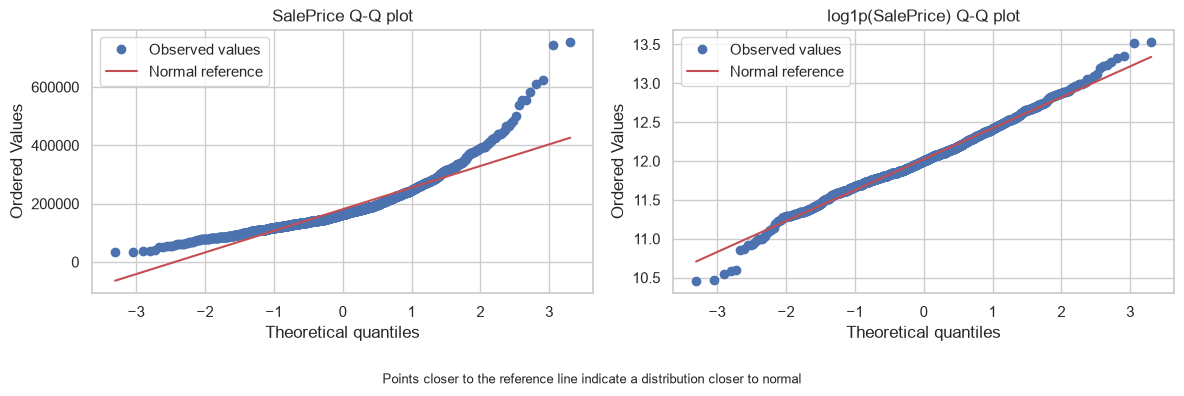

In [9]:
sale_price = df["SalePrice"]
log_sale_price = np.log1p(sale_price)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for values, title, ax in zip([sale_price, log_sale_price], ["SalePrice Q-Q plot", "log1p(SalePrice) Q-Q plot"], axes):
    stats.probplot(values, dist="norm", plot=ax)

    ax.lines[0].set_label("Observed values")
    ax.lines[1].set_label("Normal reference")
    ax.set_title(title)
    ax.legend()

fig.text(0.5, 0.02, "Points closer to the reference line indicate a distribution closer to normal", ha="center", fontsize=9)

plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

## Numeric feature skewness

Several numeric features have long right tails

They are retained without additional transformations for the current model comparison

In [10]:
numeric_features = df.select_dtypes(include="number").drop(columns=["Id", "SalePrice"])
feature_skewness = numeric_features.skew().sort_values(key=abs, ascending=False)
feature_skewness[feature_skewness.abs() > 1].to_frame("Skewness")

,Skewness
MiscVal,24.476794
PoolArea,14.828374
LotArea,12.207688
3SsnPorch,10.304342
LowQualFinSF,9.011341
KitchenAbvGr,4.488397
BsmtFinSF2,4.255261
ScreenPorch,4.122214
BsmtHalfBath,4.103403
EnclosedPorch,3.089872


## Numeric features and SalePrice

Correlations are calculated with `log1p(SalePrice)` to identify the numeric features most strongly associated with the target

In [11]:
target_correlations = numeric_features.corrwith(log_sale_price)
target_correlations = target_correlations.sort_values(key=abs, ascending=False)

target_correlations.head(15).to_frame("Correlation")

,Correlation
OverallQual,0.817185
GrLivArea,0.700927
GarageCars,0.680625
GarageArea,0.650888
TotalBsmtSF,0.612134
1stFlrSF,0.596981
FullBath,0.594771
YearBuilt,0.586570
YearRemodAdd,0.565608
GarageYrBlt,0.541073


The strongest numeric relationships are examined visually to identify trends and possible outliers

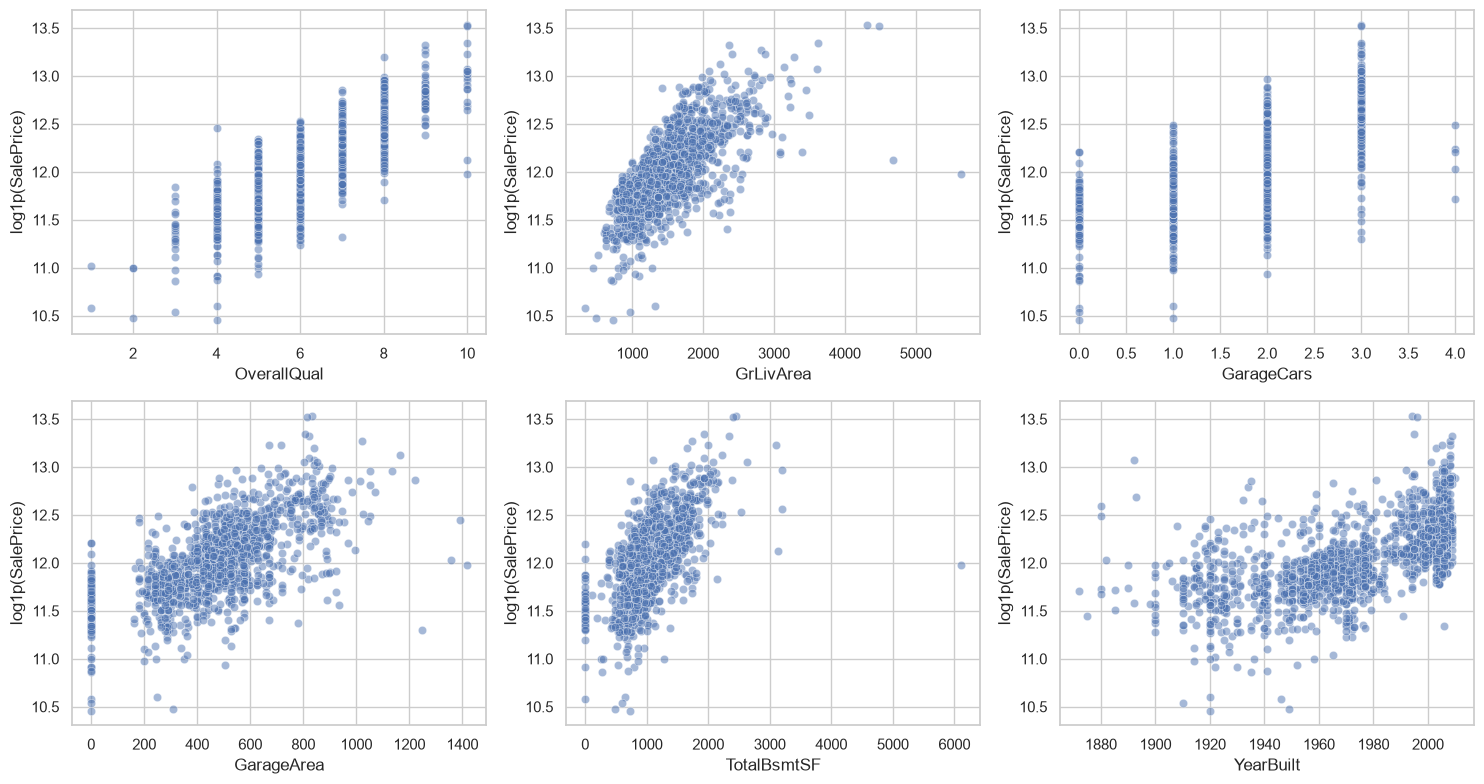

In [12]:
important_features = ["OverallQual", "GrLivArea", "GarageCars", "GarageArea", "TotalBsmtSF", "YearBuilt"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for feature, ax in zip(important_features, axes.flat):
    sns.scatterplot(data=df, x=feature, y=log_sale_price, alpha=0.5, ax=ax)
    ax.set_ylabel("log1p(SalePrice)")

plt.tight_layout()
plt.show()

## Categorical features and SalePrice

Price distributions are compared across several important categorical features

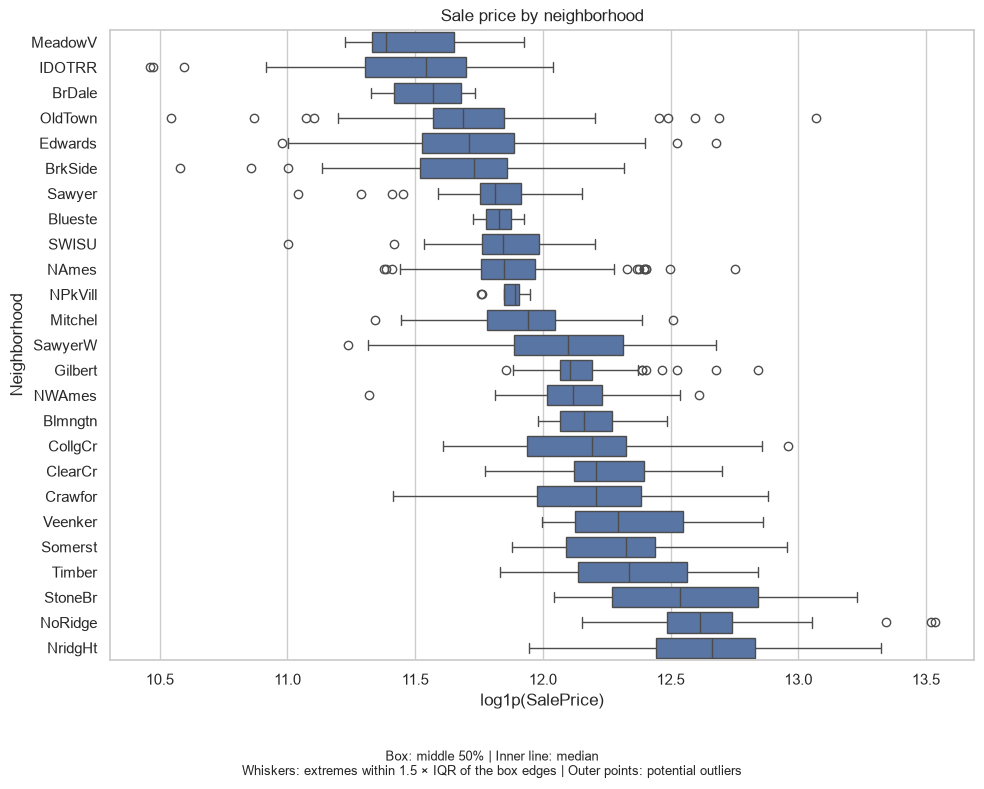

In [13]:
neighborhood_order = (df.groupby("Neighborhood")["SalePrice"].median().sort_values().index)
fig, ax = plt.subplots(figsize=(10, 8))
sns.boxplot(data=df, x=log_sale_price, y="Neighborhood", order=neighborhood_order, ax=ax)

ax.set_xlabel("log1p(SalePrice)")
ax.set_title("Sale price by neighborhood")

fig.text(0.5, 0.02, "Box: middle 50% | Inner line: median\n" "Whiskers: extremes within 1.5 × IQR of the box edges | Outer points: potential outliers", ha="center", fontsize=9)

plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

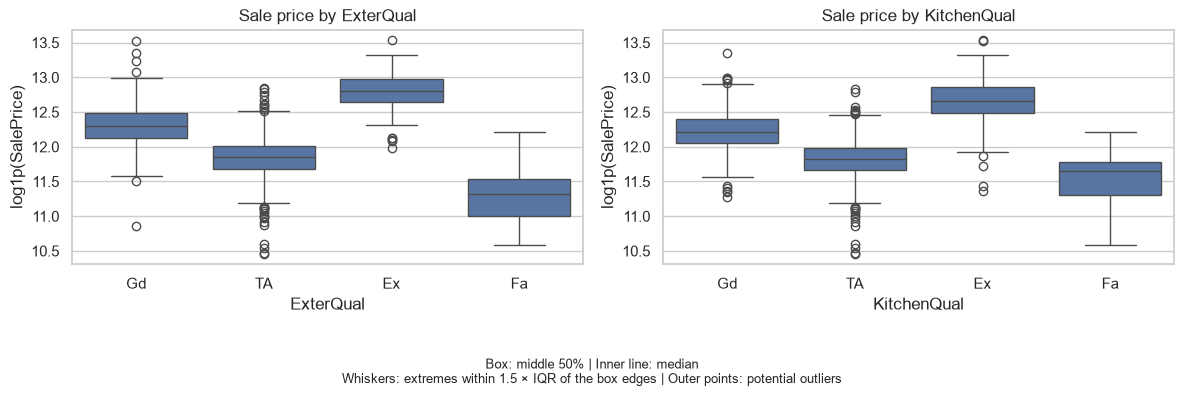

In [14]:
quality_features = ["ExterQual", "KitchenQual"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for feature, ax in zip(quality_features, axes):
    sns.boxplot(data=df, x=feature, y=log_sale_price, ax=ax)
    ax.set_ylabel("log1p(SalePrice)")
    ax.set_title(f"Sale price by {feature}")

fig.text(0.5, 0.02, "Box: middle 50% | Inner line: median\n" "Whiskers: extremes within 1.5 × IQR of the box edges | Outer points: potential outliers", ha="center", fontsize=9)

plt.tight_layout(rect=[0, 0.15, 1, 1])
plt.show()

## Potential outliers

Large houses with unusually low sale prices are inspected because they may strongly affect regression models

In [15]:
potential_outliers = df.loc[df["GrLivArea"] > 4000, ["Id", "GrLivArea", "SalePrice", "OverallQual", "Neighborhood"]]

potential_outliers.sort_values("GrLivArea", ascending=False)

,Id,GrLivArea,SalePrice,OverallQual,Neighborhood
1298,1299,5642,160000,10,Edwards
523,524,4676,184750,10,Edwards
1182,1183,4476,745000,10,NoRidge
691,692,4316,755000,10,NoRidge


Two very large houses have unusually low sale prices despite the highest overall quality

These observations may distort regression models and will be excluded from the training data

## Correlated numeric features

Relationships between similar numeric features are examined to identify potentially duplicated information

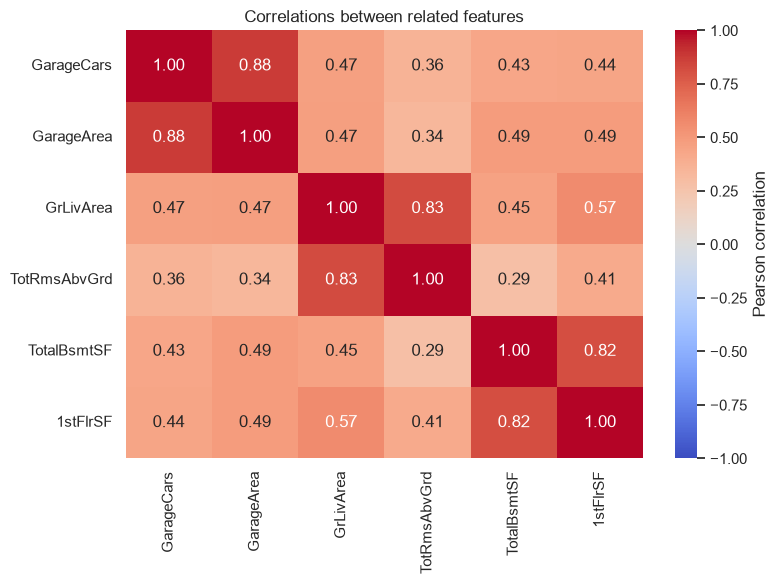

In [16]:
related_features = ["GarageCars", "GarageArea", "GrLivArea", "TotRmsAbvGrd", "TotalBsmtSF", "1stFlrSF"]
correlation_matrix = df[related_features].corr()
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, cbar_kws={"label": "Pearson correlation"}, ax=ax)

ax.set_title("Correlations between related features")

plt.tight_layout()
plt.show()

Several related features are strongly correlated, especially garage size and garage capacity

All features are retained because regularized linear models and tree-based models can handle correlated inputs

## Train and test categories

Categorical values are compared to identify categories that appear only in the test dataset

In [17]:
train_categories_df = raw_df.drop(columns="SalePrice").copy()
test_categories_df = test_df.copy()

train_categories_df["MSSubClass"] = train_categories_df["MSSubClass"].astype(str)
test_categories_df["MSSubClass"] = test_categories_df["MSSubClass"].astype(str)

raw_categorical_columns = train_categories_df.select_dtypes(include="str").columns

unseen_categories = []

for column in raw_categorical_columns:
    train_values = set(train_categories_df[column].dropna())
    test_values = set(test_categories_df[column].dropna())
    new_values = test_values - train_values

    if new_values:
        unseen_categories.append({"Feature": column,
                                  "Test-only categories": sorted(new_values)})

pd.DataFrame(unseen_categories)

,Feature,Test-only categories
0,MSSubClass,[150]


## EDA conclusions

- `SalePrice` is log-transformed to reduce right skew
- Missing values are handled inside the preprocessing pipeline
- Quality, living area, garage size and neighborhood are associated with price
- Two large low-price houses are excluded from the main experiments
- Correlated features are retained
- The encoder handles the test-only `MSSubClass` category

## Feature engineering

Related measurements are combined into aggregate features

In [18]:
def add_features(data):
    """Clean housing features and add aggregate measurements"""

    data = data.copy()
    invalid_garage_year = data["GarageYrBlt"] > data["YrSold"] + 1
    data.loc[invalid_garage_year, "GarageYrBlt"] = data.loc[invalid_garage_year, "YearBuilt"]
    data["TotalSF"] = data[["TotalBsmtSF", "1stFlrSF", "2ndFlrSF"]].sum(axis=1)
    data["TotalBathrooms"] = (data["FullBath"].fillna(0) + 0.5 * data["HalfBath"].fillna(0) + data["BsmtFullBath"].fillna(0) + 0.5 * data["BsmtHalfBath"].fillna(0))
    data["HouseAge"] = (data["YrSold"] - data["YearBuilt"]).clip(lower=0)
    data["RemodelAge"] = (data["YrSold"] - data["YearRemodAdd"]).clip(lower=0)
    data["TotalOutdoorSF"] = data[["WoodDeckSF", "OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch"]].sum(axis=1)
    data["MSSubClass"] = data["MSSubClass"].astype(str)

    return data

In [19]:
engineered_feature_names = ["TotalSF", "TotalBathrooms", "HouseAge", "RemodelAge", "TotalOutdoorSF"]
engineered_df = add_features(df)
engineered_df[engineered_feature_names].corrwith(log_sale_price).sort_values(key=abs, ascending=False).to_frame("Correlation")

,Correlation
TotalSF,0.777297
TotalBathrooms,0.673011
HouseAge,-0.587290
RemodelAge,-0.568149
TotalOutdoorSF,0.398387


`TotalSF` and `TotalBathrooms` have the strongest relationships with sale price among the engineered features

## Preprocessing pipeline

Feature engineering, missing-value handling, scaling and encoding are combined in one pipeline

In [20]:
outlier_mask = ((raw_df["GrLivArea"] > 4000) & (raw_df["SalePrice"] < 300000))

train_df = raw_df.loc[~outlier_mask].copy()

X = train_df.drop(columns=["Id", "SalePrice"])
y = np.log1p(train_df["SalePrice"])

test_ids = test_df["Id"].copy()
test_X = test_df.drop(columns="Id")

print("Train shape:", X.shape)
print("Test shape:", test_X.shape)
print("Removed outliers:", outlier_mask.sum())

Train shape: (1458, 79)
Test shape: (1459, 79)
Removed outliers: 2


In [21]:
feature_engineer = FunctionTransformer(add_features, validate=False)
engineered_X = add_features(X)

numeric_columns = engineered_X.select_dtypes(exclude="str").columns
categorical_columns = engineered_X.select_dtypes(include="str").columns
numeric_preprocessor = Pipeline([("imputer", SimpleImputer(strategy="median")),
                                 ("scaler", StandardScaler())])

categorical_preprocessor = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
                                     ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])

preprocessor = ColumnTransformer([("numeric", numeric_preprocessor, numeric_columns),
                                  ("categorical", categorical_preprocessor, categorical_columns)])

In [22]:
def make_model_pipeline(model):
    """Build a model pipeline with shared preprocessing"""

    return Pipeline([("features", clone(feature_engineer)), ("preprocessor", clone(preprocessor)), ("model", model)])

## Validation

Models are evaluated with five-fold cross-validation using RMSE on `log1p(SalePrice)`

Lower scores indicate better predictions

In [23]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

def evaluate_regressor(model, n_jobs=-1):
    """Evaluate a regressor with cross-validation"""

    scores = cross_validate(model, X, y, cv=cv, scoring="neg_root_mean_squared_error", return_train_score=True, n_jobs=n_jobs)

    return {"Train RMSE": -scores["train_score"].mean(),
            "CV RMSE": -scores["test_score"].mean(),
            "CV std": scores["test_score"].std()}

## Baseline models

Several regression models are compared using the shared preprocessing pipeline

In [24]:
baseline_models = {"Dummy Regressor": make_model_pipeline(DummyRegressor(strategy="mean")), "Linear Regression": make_model_pipeline(LinearRegression()),
                   "Ridge": make_model_pipeline(Ridge(alpha=10)),
                   "Lasso": make_model_pipeline(Lasso(alpha=0.001, max_iter=20000)),
                   "ElasticNet": make_model_pipeline(ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=20000)),
                   "KNN": make_model_pipeline(KNeighborsRegressor()),
                   "Decision Tree": make_model_pipeline(DecisionTreeRegressor(random_state=SEED)),
                   "Random Forest": make_model_pipeline(RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=1)),
                   "Linear SVR": make_model_pipeline(SVR(kernel="linear")),
                   "RBF SVR": make_model_pipeline(SVR(kernel="rbf"))}

baseline_results = []

for name, model in baseline_models.items():
    metrics = evaluate_regressor(model)
    baseline_results.append({"Model": name, **metrics})

baseline_results_df = pd.DataFrame(baseline_results)
baseline_results_df = baseline_results_df.sort_values("CV RMSE").reset_index(drop=True)

baseline_results_df.round(4)

,Model,Train RMSE,CV RMSE,CV std
0,ElasticNet,0.0974,0.1118,0.0068
1,Lasso,0.1022,0.1132,0.0074
2,Ridge,0.0937,0.1142,0.0084
3,Linear SVR,0.0924,0.1336,0.0085
4,Linear Regression,0.0857,0.1346,0.0152
5,Random Forest,0.0506,0.1361,0.0067
6,RBF SVR,0.0781,0.1407,0.0153
7,KNN,0.1351,0.1687,0.0142
8,Decision Tree,0.0000,0.2087,0.0113
9,Dummy Regressor,0.3995,0.3993,0.0168


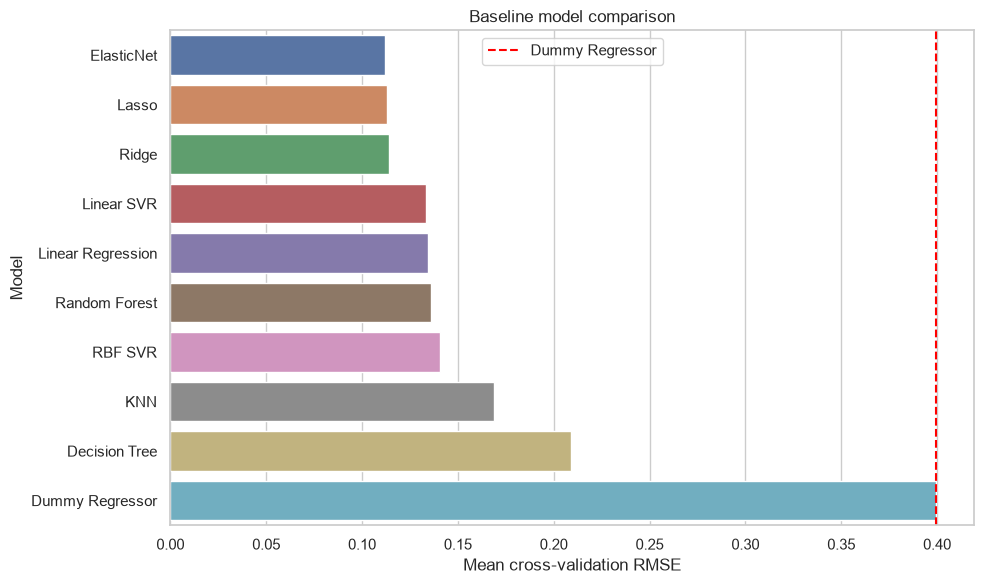

In [25]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=baseline_results_df, x="CV RMSE", y="Model", hue="Model", legend=False, ax=ax)

dummy_rmse = baseline_results_df.loc[baseline_results_df["Model"] == "Dummy Regressor", "CV RMSE"].iloc[0]
ax.axvline(dummy_rmse, color="red", linestyle="--", label="Dummy Regressor")

ax.set_xlabel("Mean cross-validation RMSE")
ax.set_ylabel("Model")
ax.set_title("Baseline model comparison")
ax.set_xlim(0, baseline_results_df["CV RMSE"].max() * 1.05)
ax.legend()

plt.tight_layout()
plt.show()

## Boosting models

Boosting models are first compared with default parameters using the shared preprocessing pipeline

In [26]:
def prepare_native_catboost_features(data):
    """Prepare categorical features for native CatBoost"""

    data = data.copy()
    data[categorical_columns] = data[categorical_columns].fillna("Missing").astype(str)

    return data

native_catboost_preprocessor = FunctionTransformer(prepare_native_catboost_features, validate=False)
native_catboost = Pipeline([("features", clone(feature_engineer)),
                            ("native_preprocessor", clone(native_catboost_preprocessor)),
                            ("model", CatBoostRegressor(cat_features=tuple(categorical_columns), loss_function="RMSE", random_seed=SEED, verbose=0, allow_writing_files=False, thread_count=1))])

In [27]:
boosting_models = {"Gradient Boosting": make_model_pipeline(GradientBoostingRegressor(random_state=SEED)),
                   "XGBoost": make_model_pipeline(xgb.XGBRegressor(objective="reg:squarederror", random_state=SEED, n_jobs=1)),
                   "LightGBM": make_model_pipeline(LGBMRegressor(objective="regression", random_state=SEED, n_jobs=1, verbosity=-1)),
                   "CatBoost One-Hot": make_model_pipeline(CatBoostRegressor(loss_function="RMSE", random_seed=SEED, verbose=0, allow_writing_files=False, thread_count=1)),
                   "CatBoost Native": native_catboost}

boosting_results = []

for name, model in boosting_models.items():
    metrics = evaluate_regressor(model)
    boosting_results.append({"Model": name, **metrics})

boosting_results_df = pd.DataFrame(boosting_results)
boosting_results_df = boosting_results_df.sort_values("CV RMSE").reset_index(drop=True)

boosting_results_df.round(4)

,Model,Train RMSE,CV RMSE,CV std
0,CatBoost One-Hot,0.0329,0.1118,0.0082
1,CatBoost Native,0.0585,0.1141,0.0068
2,Gradient Boosting,0.0744,0.1250,0.0073
3,LightGBM,0.0383,0.1265,0.0078
4,XGBoost,0.0065,0.1347,0.0046


## Hyperparameter optimization

Models are tuned with Optuna using the same five-fold cross-validation

In [28]:
def evaluate_pipeline_trial(trial, pipeline):
    """Evaluate a pipeline for one Optuna trial"""

    scores = -cross_val_score(pipeline, X, y, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
    trial.set_user_attr("CV RMSE Std", float(scores.std()))

    return float(scores.mean())


def evaluate_trial(trial, model):
    """Build and evaluate a model pipeline for one Optuna trial"""

    pipeline = make_model_pipeline(model)

    return evaluate_pipeline_trial(trial, pipeline)


def run_study(name, objective, start=None, n_trials=40):
    """Run an Optuna hyperparameter study"""

    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED), study_name=name)

    if start is not None:
        study.enqueue_trial(start)

    study.optimize(objective, n_trials=n_trials)

    print(name, "CV RMSE:", round(study.best_value, 4))
    print("CV standard deviation:", round(study.best_trial.user_attrs["CV RMSE Std"], 4))
    print("Best parameters:", study.best_params)

    return study

In [29]:
def elastic_net_objective(trial):
    """Optimize ElasticNet with cross-validation"""

    parameters = {"alpha": trial.suggest_float("alpha", 1e-5, 1e-2, log=True),
                  "l1_ratio": trial.suggest_float("l1_ratio", 0.05, 0.95, step=0.05)}

    model = ElasticNet(**parameters, max_iter=20000)

    return evaluate_trial(trial, model)

elastic_net_start = {"alpha": 0.001, "l1_ratio": 0.5}
elastic_net_study = run_study("ElasticNet", elastic_net_objective, elastic_net_start)
best_optuna_elastic_net = make_model_pipeline(ElasticNet(**elastic_net_study.best_params, max_iter=20000))

ElasticNet CV RMSE: 0.1117
CV standard deviation: 0.0068
Best parameters: {'alpha': 0.0007623983153817533, 'l1_ratio': 0.7500000000000001}


In [30]:
def suggest_catboost_parameters(trial):
    """Suggest CatBoost parameters for an Optuna trial"""

    return {"iterations": trial.suggest_int("iterations", 300, 1200, step=100),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
            "depth": trial.suggest_int("depth", 3, 7),
            "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1, 20, log=True),
            "random_strength": trial.suggest_float("random_strength", 0.1, 5, log=True),
            "border_count": trial.suggest_categorical("border_count", [32, 64, 128])}

def catboost_objective(trial):
    """Optimize one-hot CatBoost with cross-validation"""

    parameters = suggest_catboost_parameters(trial)
    model = CatBoostRegressor(**parameters, loss_function="RMSE", random_seed=SEED, verbose=0, allow_writing_files=False, thread_count=1)

    return evaluate_trial(trial, model)

catboost_start = {"iterations": 500,
                  "learning_rate": 0.03,
                  "depth": 5, "l2_leaf_reg": 5.0,
                  "random_strength": 1.0,
                  "border_count": 64}

catboost_study = run_study("CatBoost One-Hot", catboost_objective, catboost_start)
best_optuna_catboost = make_model_pipeline(CatBoostRegressor(**catboost_study.best_params, loss_function="RMSE", random_seed=SEED, verbose=0, allow_writing_files=False, thread_count=1))

CatBoost One-Hot CV RMSE: 0.1111
CV standard deviation: 0.0083
Best parameters: {'iterations': 1200, 'learning_rate': 0.030023005574603863, 'depth': 5, 'l2_leaf_reg': 1.767354970433315, 'random_strength': 3.721911570978738, 'border_count': 128}


In [31]:
def make_native_catboost(parameters):
    """Build a CatBoost pipeline with native categorical features"""

    return Pipeline([("features", clone(feature_engineer)),
                     ("native_preprocessor", clone(native_catboost_preprocessor)),
                     ("model",CatBoostRegressor(**parameters, cat_features=tuple(categorical_columns), loss_function="RMSE", random_seed=SEED, verbose=0, allow_writing_files=False, thread_count=1))])

def native_catboost_objective(trial):
    """Optimize native CatBoost with cross-validation"""

    parameters = suggest_catboost_parameters(trial)
    pipeline = make_native_catboost(parameters)

    return evaluate_pipeline_trial(trial, pipeline)

native_catboost_study = run_study("CatBoost Native", native_catboost_objective, catboost_start)
best_optuna_native_catboost = make_native_catboost(native_catboost_study.best_params)

CatBoost Native CV RMSE: 0.1127
CV standard deviation: 0.0069
Best parameters: {'iterations': 1200, 'learning_rate': 0.04052350645556555, 'depth': 5, 'l2_leaf_reg': 1.0507741616162165, 'random_strength': 1.711087024589989, 'border_count': 128}


In [32]:
def gradient_boosting_objective(trial):
    """Optimize Gradient Boosting with cross-validation"""

    parameters = {"n_estimators": trial.suggest_int("n_estimators", 200, 1000, step=100),
                  "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
                  "max_depth": trial.suggest_int("max_depth", 2, 5),
                  "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
                  "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 15),
                  "subsample": trial.suggest_float("subsample", 0.6, 1.0, step=0.1),
                  "max_features": trial.suggest_categorical("max_features", [None, "sqrt", "log2"]),
                  "loss": trial.suggest_categorical("loss", ["squared_error", "huber"])}

    model = GradientBoostingRegressor(**parameters, random_state=SEED)

    return evaluate_trial(trial, model)


gradient_boosting_start = {"n_estimators": 500,
                           "learning_rate": 0.03,
                           "max_depth": 3,
                           "min_samples_split": 10,
                           "min_samples_leaf": 5,
                           "subsample": 0.8,
                           "max_features": None,
                           "loss": "huber"}

gradient_boosting_study = run_study("Gradient Boosting", gradient_boosting_objective, gradient_boosting_start)
best_optuna_gradient_boosting = make_model_pipeline(GradientBoostingRegressor(**gradient_boosting_study.best_params, random_state=SEED))

Gradient Boosting CV RMSE: 0.1154
CV standard deviation: 0.0042
Best parameters: {'n_estimators': 900, 'learning_rate': 0.0410623103787927, 'max_depth': 3, 'min_samples_split': 14, 'min_samples_leaf': 3, 'subsample': 0.6, 'max_features': None, 'loss': 'squared_error'}


In [33]:
def xgboost_objective(trial):
    """Optimize XGBoost with cross-validation"""

    parameters = {"n_estimators": trial.suggest_int("n_estimators", 300, 1500, step=100),
                  "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
                  "max_depth": trial.suggest_int("max_depth", 2, 6),
                  "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
                  "subsample": trial.suggest_float("subsample", 0.6, 1.0, step=0.1),
                  "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0, step=0.1),
                  "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 1.0, log=True),
                  "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 20.0, log=True)}

    model = xgb.XGBRegressor(**parameters, objective="reg:squarederror", tree_method="hist", random_state=SEED, n_jobs=1)

    return evaluate_trial(trial, model)

xgboost_start = {"n_estimators": 800,
                 "learning_rate": 0.03,
                 "max_depth": 3,
                 "min_child_weight": 1,
                 "subsample": 0.8,
                 "colsample_bytree": 0.8,
                 "reg_alpha": 0.001,
                 "reg_lambda": 1.0}

xgboost_study = run_study("XGBoost", xgboost_objective, xgboost_start)
best_optuna_xgboost = make_model_pipeline(xgb.XGBRegressor(**xgboost_study.best_params, objective="reg:squarederror", tree_method="hist", random_state=SEED, n_jobs=1))

XGBoost CV RMSE: 0.1131
CV standard deviation: 0.0057
Best parameters: {'n_estimators': 700, 'learning_rate': 0.05873416798780296, 'max_depth': 4, 'min_child_weight': 2, 'subsample': 0.8, 'colsample_bytree': 0.6, 'reg_alpha': 0.009688563942802705, 'reg_lambda': 0.2759126300914537}


In [34]:
def lightgbm_objective(trial):
    """Optimize LightGBM with cross-validation"""

    parameters = {"n_estimators": trial.suggest_int("n_estimators", 300, 1500, step=100),
                  "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
                  "num_leaves": trial.suggest_int("num_leaves", 8, 64),
                  "max_depth": trial.suggest_int("max_depth", 3, 8),
                  "min_child_samples": trial.suggest_int("min_child_samples", 5, 40),
                  "subsample": trial.suggest_float("subsample", 0.6, 1.0, step=0.1),
                  "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0, step=0.1),
                  "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 1.0, log=True),
                  "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 20.0, log=True)}

    model = LGBMRegressor(**parameters, objective="regression", subsample_freq=1, random_state=SEED, n_jobs=1, verbosity=-1)

    return evaluate_trial(trial, model)

lightgbm_start = {"n_estimators": 800,
                  "learning_rate": 0.03,
                  "num_leaves": 20,
                  "max_depth": 5,
                  "min_child_samples": 20,
                  "subsample": 0.8,
                  "colsample_bytree": 0.8,
                  "reg_alpha": 0.001,
                  "reg_lambda": 1.0}

lightgbm_study = run_study("LightGBM", lightgbm_objective, lightgbm_start)
best_optuna_lightgbm = make_model_pipeline(LGBMRegressor(**lightgbm_study.best_params, objective="regression", subsample_freq=1, random_state=SEED, n_jobs=1, verbosity=-1))

LightGBM CV RMSE: 0.1136
CV standard deviation: 0.0073
Best parameters: {'n_estimators': 1200, 'learning_rate': 0.02097564342536148, 'num_leaves': 14, 'max_depth': 8, 'min_child_samples': 5, 'subsample': 0.6, 'colsample_bytree': 0.6, 'reg_alpha': 0.003013967278292442, 'reg_lambda': 5.731422471592583}


In [35]:
def random_forest_objective(trial):
    """Optimize Random Forest with cross-validation"""

    parameters = {"n_estimators": trial.suggest_int("n_estimators", 300, 900, step=100),
                  "max_depth": trial.suggest_int("max_depth", 5, 30),
                  "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
                  "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
                  "max_features": trial.suggest_categorical("max_features", ["sqrt", 0.3, 0.5, 0.7, 1.0])}

    model = RandomForestRegressor(**parameters, random_state=SEED, n_jobs=1)

    return evaluate_trial(trial, model)

random_forest_start = {"n_estimators": 500,
                       "max_depth": 20,
                       "min_samples_split": 2,
                       "min_samples_leaf": 1,
                       "max_features": 1.0}

random_forest_study = run_study("Random Forest", random_forest_objective, random_forest_start, n_trials=25)
best_optuna_random_forest = make_model_pipeline(RandomForestRegressor(**random_forest_study.best_params, random_state=SEED, n_jobs=1))

Random Forest CV RMSE: 0.1306
CV standard deviation: 0.0076
Best parameters: {'n_estimators': 300, 'max_depth': 13, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.3}


In [36]:
def svr_objective(trial):
    """Optimize RBF SVR with cross-validation"""

    parameters = {"C": trial.suggest_float("C", 0.1, 100.0, log=True),
                  "epsilon": trial.suggest_float("epsilon", 1e-3, 0.1, log=True),
                  "gamma": trial.suggest_float("gamma", 1e-5, 0.1, log=True)}

    model = SVR(**parameters, kernel="rbf")

    return evaluate_trial(trial, model)

svr_start = {"C": 10.0,
             "epsilon": 0.01,
             "gamma": 0.001}

svr_study = run_study("RBF SVR", svr_objective, svr_start)
best_optuna_svr = make_model_pipeline(SVR(**svr_study.best_params, kernel="rbf"))

RBF SVR CV RMSE: 0.1113
CV standard deviation: 0.0098
Best parameters: {'C': 18.4625000498051, 'epsilon': 0.004342457951180244, 'gamma': 0.00042166943832873887}


In [37]:
def ridge_objective(trial):
    """Optimize Ridge with cross-validation"""

    alpha = trial.suggest_float("alpha", 1e-3, 1e3, log=True)

    model = Ridge(alpha=alpha)

    return evaluate_trial(trial, model)

ridge_start = {"alpha": 10.0}
ridge_study = run_study("Ridge", ridge_objective, ridge_start)
best_optuna_ridge = make_model_pipeline(Ridge(**ridge_study.best_params))

Ridge CV RMSE: 0.1138
CV standard deviation: 0.0085
Best parameters: {'alpha': 21.538517272483972}


In [38]:
def lasso_objective(trial):
    """Optimize Lasso with cross-validation"""

    alpha = trial.suggest_float("alpha", 1e-5, 1e-2, log=True)
    model = Lasso(alpha=alpha, max_iter=20000)

    return evaluate_trial(trial, model)

lasso_start = {"alpha": 0.001}
lasso_study = run_study("Lasso", lasso_objective, lasso_start)
best_optuna_lasso = make_model_pipeline(Lasso(**lasso_study.best_params, max_iter=20000))

Lasso CV RMSE: 0.1116
CV standard deviation: 0.0066
Best parameters: {'alpha': 0.0005098460288377917}


In [39]:
def knn_objective(trial):
    """Optimize KNN with cross-validation"""

    parameters = {"n_neighbors": trial.suggest_int("n_neighbors", 3, 30),
                  "weights": trial.suggest_categorical("weights", ["uniform", "distance"]),
                  "p": trial.suggest_int("p", 1, 2)}

    model = KNeighborsRegressor(**parameters)

    return evaluate_trial(trial, model)

knn_start = {"n_neighbors": 5,
             "weights": "uniform",
             "p": 2}

knn_study = run_study("KNN", knn_objective, knn_start, n_trials=25)
best_optuna_knn = make_model_pipeline(KNeighborsRegressor(**knn_study.best_params))

KNN CV RMSE: 0.1573
CV standard deviation: 0.0111
Best parameters: {'n_neighbors': 6, 'weights': 'distance', 'p': 1}


In [40]:
def decision_tree_objective(trial):
    """Optimize Decision Tree with cross-validation"""

    parameters = {"max_depth": trial.suggest_int("max_depth", 2, 20),
                  "min_samples_split": trial.suggest_int("min_samples_split", 2, 30),
                  "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 15),
                  "max_features": trial.suggest_categorical("max_features", [None, "sqrt", "log2", 0.5, 0.8])}

    model = DecisionTreeRegressor(**parameters, random_state=SEED)

    return evaluate_trial(trial, model)

decision_tree_start = {"max_depth": 10,
                       "min_samples_split": 5,
                       "min_samples_leaf": 2,
                       "max_features": None}

decision_tree_study = run_study("Decision Tree", decision_tree_objective, decision_tree_start, n_trials=25)
best_optuna_decision_tree = make_model_pipeline(DecisionTreeRegressor(**decision_tree_study.best_params, random_state=SEED))

Decision Tree CV RMSE: 0.1753
CV standard deviation: 0.0122
Best parameters: {'max_depth': 10, 'min_samples_split': 26, 'min_samples_leaf': 12, 'max_features': 0.8}


In [41]:
def make_bagging_model(parameters):
    """Build a Bagging regressor with a Decision Tree estimator"""

    tree = DecisionTreeRegressor(max_depth=parameters["tree_max_depth"],
                                 min_samples_leaf=parameters["tree_min_samples_leaf"],
                                 random_state=SEED)

    return BaggingRegressor(estimator=tree,
                            n_estimators=parameters["n_estimators"],
                            max_samples=parameters["max_samples"],
                            max_features=parameters["max_features"],
                            bootstrap=parameters["bootstrap"],
                            random_state=SEED,
                            n_jobs=1)

def bagging_objective(trial):
    """Optimize Bagging with cross-validation"""

    parameters = {"tree_max_depth": trial.suggest_int("tree_max_depth", 3, 20),
                  "tree_min_samples_leaf": trial.suggest_int("tree_min_samples_leaf", 1, 15),
                  "n_estimators": trial.suggest_int("n_estimators", 50, 300, step=50),
                  "max_samples": trial.suggest_float("max_samples", 0.5, 1.0, step=0.1),
                  "max_features": trial.suggest_float("max_features", 0.5, 1.0, step=0.1),
                  "bootstrap": trial.suggest_categorical("bootstrap", [True, False])}

    model = make_bagging_model(parameters)

    return evaluate_trial(trial, model)

bagging_start = {"tree_max_depth": 15,
                 "tree_min_samples_leaf": 2,
                 "n_estimators": 100,
                 "max_samples": 0.8,
                 "max_features": 0.8,
                 "bootstrap": True}

bagging_study = run_study("Bagging Decision Tree", bagging_objective, bagging_start, n_trials=25)
best_optuna_bagging = make_model_pipeline(make_bagging_model(bagging_study.best_params))

Bagging Decision Tree CV RMSE: 0.1307
CV standard deviation: 0.0073
Best parameters: {'tree_max_depth': 16, 'tree_min_samples_leaf': 1, 'n_estimators': 150, 'max_samples': 0.6, 'max_features': 0.5, 'bootstrap': False}


## PyTorch DNN

A neural network with two hidden layers is evaluated using the same preprocessing and cross-validation

Training uses MSELoss on standardized log prices, with the number of epochs selected through cross-validation

Early stopping is not used

In [42]:
def build_dnn(parameters, input_size):
    """Build a two-layer neural network for regression"""

    activation_classes = {"ReLU": nn.ReLU,
                          "LeakyReLU": nn.LeakyReLU,
                          "ELU": nn.ELU}

    activation_class = activation_classes[parameters["activation"]]
    layers = [nn.Linear(input_size, parameters["hidden_size_1"]), activation_class()]

    if parameters["batch_norm"]:
        layers.append(nn.BatchNorm1d(parameters["hidden_size_1"]))

    layers.extend([nn.Dropout(parameters["dropout_1"]),
                   nn.Linear(parameters["hidden_size_1"], parameters["hidden_size_2"]),
                   activation_class(),
                   nn.Dropout(parameters["dropout_2"]),
                   nn.Linear(parameters["hidden_size_2"], 1)])

    return nn.Sequential(*layers)

In [43]:
def train_torch_model(parameters, features, targets, seed, model_factory):
    """Train a PyTorch model with a fixed random seed"""

    torch.manual_seed(seed)
    np.random.seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    feature_tensor = torch.tensor(np.asarray(features), dtype=torch.float32)
    target_tensor = torch.tensor(np.asarray(targets), dtype=torch.float32).reshape(-1, 1)
    generator = torch.Generator().manual_seed(seed)

    train_loader = DataLoader(TensorDataset(feature_tensor, target_tensor), batch_size=parameters["batch_size"], shuffle=True, generator=generator, drop_last=parameters["batch_norm"])

    model = model_factory(feature_tensor.shape[1]).to(device)
    criterion = nn.MSELoss()
    optimizer_class = (torch.optim.AdamW if parameters["optimizer"] == "AdamW" else torch.optim.Adam)
    optimizer = optimizer_class(model.parameters(), lr=parameters["learning_rate"], weight_decay=parameters["weight_decay"])
    scheduler = None

    if parameters["scheduler"] == "Cosine":
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=parameters["epochs"], eta_min=1e-5)

    for _ in range(parameters["epochs"]):
        model.train()

        for batch_features, batch_targets in train_loader:
            batch_features = batch_features.to(device)
            batch_targets = batch_targets.to(device)

            optimizer.zero_grad()
            loss = criterion(model(batch_features), batch_targets)
            loss.backward()
            optimizer.step()

        if scheduler is not None:
            scheduler.step()

    model.eval()

    return model, device


def train_dnn(parameters, features, targets, seed):
    """Train the one-hot DNN"""

    return train_torch_model(parameters, features, targets, seed,
                             lambda input_size: build_dnn(parameters, input_size))

In [44]:
class TorchDNNRegressor(RegressorMixin, BaseEstimator):
    """Use the PyTorch DNN through the sklearn estimator interface"""

    def __init__(self, parameters=None, random_state=42):
        self.parameters = parameters
        self.random_state = random_state

    def fit(self, X, y):
        """Train the DNN regressor on the input data"""

        if self.parameters is None:
            raise ValueError("DNN parameters are required")

        features = np.asarray(X)
        targets = np.asarray(y, dtype=np.float32)

        self.target_mean_ = float(targets.mean())
        self.target_std_ = float(targets.std())
        scaled_targets = (targets - self.target_mean_) / self.target_std_

        self.model_, self.device_ = train_dnn(self.parameters, features, scaled_targets, self.random_state)

        self.n_features_in_ = features.shape[1]

        return self

    def predict(self, X):
        """Return predicted target values"""

        features = torch.tensor(np.asarray(X), dtype=torch.float32, device=self.device_)

        with torch.no_grad():
            scaled_predictions = self.model_(features).cpu().numpy().ravel()

        return scaled_predictions * self.target_std_ + self.target_mean_

In [45]:
def dnn_objective(trial):
    """Optimize the DNN with cross-validation"""

    parameters = {"hidden_size_1": trial.suggest_categorical("hidden_size_1", [64, 128, 256]),
                  "hidden_size_2": trial.suggest_categorical("hidden_size_2", [32, 64, 128]),
                  "dropout_1": trial.suggest_float("dropout_1", 0.0, 0.4, step=0.1),
                  "dropout_2": trial.suggest_float("dropout_2", 0.0, 0.4, step=0.1),
                  "learning_rate": trial.suggest_float("learning_rate", 1e-4, 3e-3, log=True),
                  "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True),
                  "batch_size": trial.suggest_categorical("batch_size", [32, 64, 128]),
                  "epochs": trial.suggest_int("epochs", 50, 200, step=25),
                  "activation": trial.suggest_categorical("activation", ["ReLU", "LeakyReLU", "ELU"]),
                  "batch_norm": trial.suggest_categorical("batch_norm", [True, False]),
                  "optimizer": trial.suggest_categorical("optimizer", ["Adam", "AdamW"]),
                  "scheduler": trial.suggest_categorical("scheduler", ["None", "Cosine"])}

    fold_scores = []

    for fold_number, indexes in enumerate(cv.split(X)):
        train_index, validation_index = indexes
        fold_seed = SEED + fold_number

        fold_train_X = X.iloc[train_index]
        fold_validation_X = X.iloc[validation_index]
        fold_train_y = y.iloc[train_index]
        fold_validation_y = y.iloc[validation_index]
        fold_transformer = Pipeline([("features", clone(feature_engineer)),
                                     ("preprocessor", clone(preprocessor))])

        train_data = fold_transformer.fit_transform(fold_train_X, fold_train_y)

        validation_data = fold_transformer.transform(fold_validation_X)

        target_mean = float(fold_train_y.mean())
        target_std = float(fold_train_y.to_numpy().std())

        scaled_train_y = (fold_train_y - target_mean) / target_std
        model, device = train_dnn(parameters, train_data, scaled_train_y, fold_seed)
        validation_tensor = torch.tensor(validation_data, dtype=torch.float32, device=device)

        with torch.no_grad():
            scaled_predictions = model(validation_tensor).cpu().numpy().ravel()

        predictions = scaled_predictions * target_std + target_mean

        rmse = np.sqrt(np.mean((fold_validation_y.to_numpy() - predictions) ** 2))
        fold_scores.append(rmse)

        trial.report(float(np.mean(fold_scores)), step=fold_number)

        if trial.should_prune():
            raise optuna.TrialPruned()

        del model

        if device.type == "cuda":
            torch.cuda.empty_cache()

    trial.set_user_attr("CV RMSE Std", float(np.std(fold_scores)))

    return float(np.mean(fold_scores))

In [46]:
dnn_sampler = optuna.samplers.TPESampler(seed=SEED)
dnn_pruner = optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2)
dnn_study = optuna.create_study(direction="minimize", sampler=dnn_sampler, pruner=dnn_pruner, study_name="PyTorch DNN")

dnn_study.enqueue_trial({"hidden_size_1": 128,
                         "hidden_size_2": 64,
                         "dropout_1": 0.2,
                         "dropout_2": 0.1,
                         "learning_rate": 0.001,
                         "weight_decay": 0.0001,
                         "batch_size": 64,
                         "epochs": 100,
                         "activation": "ReLU",
                         "batch_norm": True,
                         "optimizer": "AdamW",
                         "scheduler": "Cosine"})

dnn_study.optimize(dnn_objective, n_trials=30)

print("DNN CV RMSE:", round(dnn_study.best_value, 4))
print("CV standard deviation:",round(dnn_study.best_trial.user_attrs["CV RMSE Std"], 4))
print("Best parameters:", dnn_study.best_params)

best_optuna_dnn = make_model_pipeline(TorchDNNRegressor(parameters=dnn_study.best_params, random_state=SEED))

DNN CV RMSE: 0.1128
CV standard deviation: 0.0083
Best parameters: {'hidden_size_1': 256, 'hidden_size_2': 64, 'dropout_1': 0.4, 'dropout_2': 0.0, 'learning_rate': 0.00013280145178866016, 'weight_decay': 0.0010078448876277442, 'batch_size': 128, 'epochs': 50, 'activation': 'LeakyReLU', 'batch_norm': False, 'optimizer': 'Adam', 'scheduler': 'None'}


### DNN learning curves

A separate run on the first CV split tracks training and validation loss after each epoch

Both losses are evaluated with dropout disabled

Parameters and the number of epochs remain fixed, without checkpoint selection or early stopping

These curves are a development diagnostic, not an independent test

In [47]:
from config import DNN_PARAMS


def plot_dnn_losses(parameters, train_features, train_targets, validation_features, validation_targets, criterion, use_cuda=False):
    """Plot losses for a separate fixed-parameter DNN run"""

    device = torch.device("cuda" if use_cuda and torch.cuda.is_available() else "cpu")

    train_tensor = torch.tensor(np.asarray(train_features), dtype=torch.float32)
    train_target = torch.tensor(np.asarray(train_targets), dtype=torch.float32).reshape(-1, 1)

    validation_tensor = torch.tensor(np.asarray(validation_features), dtype=torch.float32, device=device)
    validation_target = torch.tensor(np.asarray(validation_targets), dtype=torch.float32, device=device).reshape(-1, 1)

    history = {"Train loss": [], "Validation loss": []}

    # Restore random states after the diagnostic run
    with torch.random.fork_rng():
        torch.manual_seed(SEED)

        model = build_dnn(parameters, train_tensor.shape[1]).to(device)
        loader = DataLoader(TensorDataset(train_tensor, train_target), batch_size=parameters["batch_size"], shuffle=True, generator=torch.Generator().manual_seed(SEED), drop_last=parameters["batch_norm"])
        optimizer_class = (torch.optim.AdamW if parameters["optimizer"] == "AdamW" else torch.optim.Adam)
        optimizer = optimizer_class(model.parameters(), lr=parameters["learning_rate"], weight_decay=parameters["weight_decay"])

        scheduler = None

        if parameters["scheduler"] == "Cosine":
            scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=parameters["epochs"], eta_min=1e-5)

        for _ in range(parameters["epochs"]):
            model.train()

            for batch_features, batch_targets in loader:
                optimizer.zero_grad()

                loss = criterion(model(batch_features.to(device)), batch_targets.to(device))

                loss.backward()
                optimizer.step()

            if scheduler is not None:
                scheduler.step()

            model.eval()

            # Measure both losses in evaluation mode
            with torch.no_grad():
                train_loss = criterion(model(train_tensor.to(device)), train_target.to(device))
                validation_loss = criterion(model(validation_tensor), validation_target)

            history["Train loss"].append(train_loss.item())
            history["Validation loss"].append(validation_loss.item())

    fig, ax = plt.subplots(figsize=(8, 4))
    epochs = range(1, parameters["epochs"] + 1)

    for name, values in history.items():
        ax.plot(epochs, values, label=name)

    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.set_title("DNN learning curves - one validation fold")
    ax.legend()

    plt.tight_layout()
    plt.show()

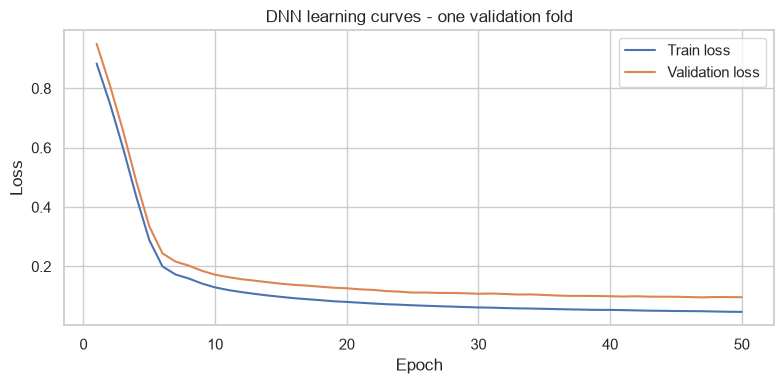

In [48]:
diagnostic_train_index, diagnostic_val_index = next(cv.split(X))
diagnostic_transformer = Pipeline([("features", clone(feature_engineer)),("preprocessor", clone(preprocessor))])

diagnostic_train_data = diagnostic_transformer.fit_transform(X.iloc[diagnostic_train_index], y.iloc[diagnostic_train_index])

diagnostic_val_data = diagnostic_transformer.transform(X.iloc[diagnostic_val_index])

diagnostic_train_y = y.iloc[diagnostic_train_index].to_numpy(dtype=np.float32)
diagnostic_val_y = y.iloc[diagnostic_val_index].to_numpy(dtype=np.float32)

# Learn target scaling from the training fold only
diagnostic_target_mean = diagnostic_train_y.mean()
diagnostic_target_std = diagnostic_train_y.std()

plot_dnn_losses(parameters=DNN_PARAMS,
                train_features=diagnostic_train_data,
                train_targets=(diagnostic_train_y - diagnostic_target_mean) / diagnostic_target_std,
                validation_features=diagnostic_val_data,
                validation_targets=(diagnostic_val_y - diagnostic_target_mean) / diagnostic_target_std,
                criterion=nn.MSELoss(),
                use_cuda=True)

### DNN with categorical embeddings

This experiment replaces one-hot encoding with trainable embeddings while keeping the selected DNN parameters

In [49]:
embedding_preprocessor = ColumnTransformer([("categorical",Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
                                                                     ("ordinal",OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))]),categorical_columns),
                                            ("numeric",clone(numeric_preprocessor), numeric_columns)])

In [50]:
class EmbeddingNetwork(nn.Module):
    """Combine categorical embeddings with numeric features"""

    def __init__(self, category_sizes, numeric_count, parameters):
        super().__init__()

        dimensions = [max(2, min(16, size // 2)) for size in category_sizes]
        self.embeddings = nn.ModuleList([nn.Embedding(size, dimension, padding_idx=0) for size, dimension in zip(category_sizes, dimensions)])
        self.mlp = build_dnn(parameters, sum(dimensions) + numeric_count)

    def forward(self, features):
        """Combine embedded and numeric features"""

        category_count = len(self.embeddings)
        categorical = features[:, :category_count].long() + 1
        numeric = features[:, category_count:]
        embedded = [layer(categorical[:, index]) for index, layer in enumerate(self.embeddings)]
        combined = torch.cat(embedded + [numeric], dim=1)

        return self.mlp(combined)

In [51]:
class EmbeddingDNNRegressor(RegressorMixin, BaseEstimator):
    """Use the embedding DNN through the sklearn interface"""

    def __init__(self, category_count, numeric_count, parameters=None, random_state=42):
        self.category_count = category_count
        self.numeric_count = numeric_count
        self.parameters = parameters
        self.random_state = random_state

    def fit(self, X, y):
        """Train the embedding DNN regressor"""

        if self.parameters is None:
            raise ValueError("DNN parameters are required")

        features = np.asarray(X)
        targets = np.asarray(y, dtype=np.float32)

        category_sizes = tuple(int(features[:, index].max()) + 2 for index in range(self.category_count))

        self.target_mean_ = float(targets.mean())
        self.target_std_ = float(targets.std())

        scaled_targets = (targets - self.target_mean_) / self.target_std_

        def model_factory(_):
            return EmbeddingNetwork(category_sizes, self.numeric_count, self.parameters)

        self.model_, self.device_ = train_torch_model(self.parameters, features, scaled_targets, self.random_state, model_factory)
        self.n_features_in_ = features.shape[1]

        return self

    def predict(self, X):
        """Return predicted target values"""

        features = torch.tensor(np.asarray(X), dtype=torch.float32, device=self.device_)

        with torch.no_grad():
            scaled_predictions = self.model_(features).cpu().numpy().ravel()

        return (scaled_predictions * self.target_std_ + self.target_mean_)

In [52]:
embedding_dnn = Pipeline([("features", clone(feature_engineer)),
                          ("preprocessor", clone(embedding_preprocessor)),
                          ("model", EmbeddingDNNRegressor(category_count=len(categorical_columns), numeric_count=len(numeric_columns), parameters=dnn_study.best_params, random_state=SEED))])

embedding_dnn_metrics = evaluate_regressor(embedding_dnn, n_jobs=1)

pd.DataFrame([{"Model": "PyTorch DNN Embeddings", **embedding_dnn_metrics}]).round(4)

,Model,Train RMSE,CV RMSE,CV std
0,PyTorch DNN Embeddings,0.0911,0.1196,0.007


## Single-model comparison

Tuned models and the embedding experiment are compared using the same five-fold cross-validation

In [53]:
tuned_studies = {"CatBoost One-Hot": catboost_study,
                 "CatBoost Native": native_catboost_study,
                 "RBF SVR": svr_study,
                 "ElasticNet": elastic_net_study,
                 "Lasso": lasso_study,
                 "Ridge": ridge_study,
                 "Gradient Boosting": gradient_boosting_study,
                 "XGBoost": xgboost_study,
                 "LightGBM": lightgbm_study,
                 "Random Forest": random_forest_study,
                 "KNN": knn_study,
                 "Decision Tree": decision_tree_study,
                 "Bagging Decision Tree": bagging_study,
                 "PyTorch DNN": dnn_study}

tuned_results = []

for name, study in tuned_studies.items():
    tuned_results.append({"Model": name, "CV RMSE": study.best_value, "CV std": study.best_trial.user_attrs["CV RMSE Std"]})

tuned_results.append({"Model": "PyTorch DNN Embeddings", "CV RMSE": embedding_dnn_metrics["CV RMSE"], "CV std": embedding_dnn_metrics["CV std"]})
tuned_results_df = pd.DataFrame(tuned_results)
tuned_results_df = tuned_results_df.sort_values("CV RMSE").reset_index(drop=True)

tuned_results_df.round(4)

,Model,CV RMSE,CV std
0,CatBoost One-Hot,0.1111,0.0083
1,RBF SVR,0.1113,0.0098
2,Lasso,0.1116,0.0066
3,ElasticNet,0.1117,0.0068
4,CatBoost Native,0.1127,0.0069
5,PyTorch DNN,0.1128,0.0083
6,XGBoost,0.1131,0.0057
7,LightGBM,0.1136,0.0073
8,Ridge,0.1138,0.0085
9,Gradient Boosting,0.1154,0.0042


Categorical embeddings did not improve CV RMSE with the parameters transferred from the one-hot DNN

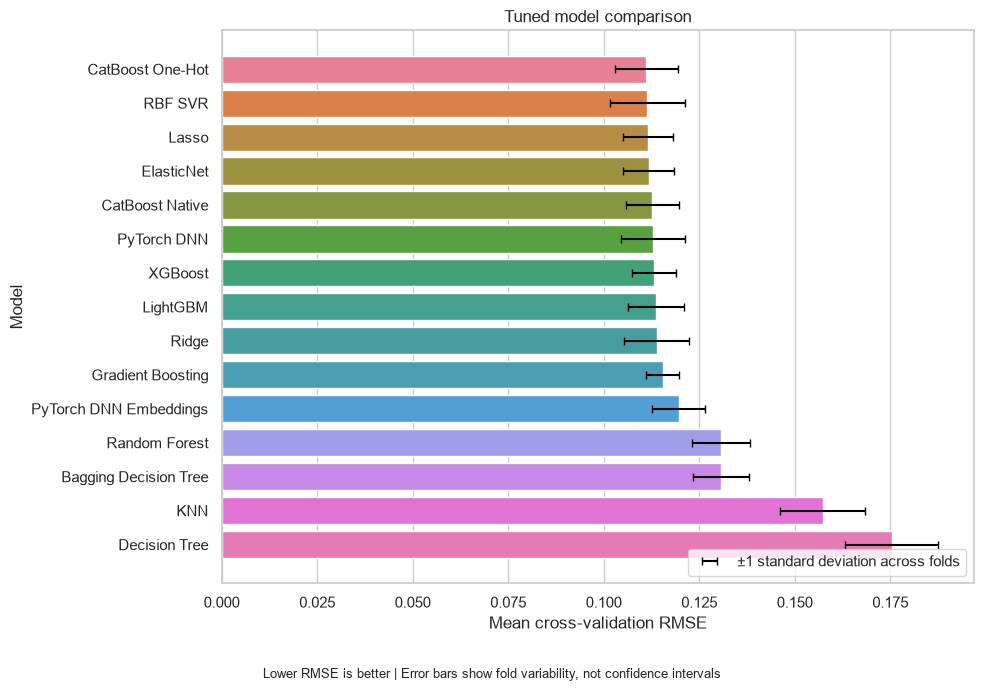

In [54]:
model_order = tuned_results_df["Model"].tolist()
fig, ax = plt.subplots(figsize=(10, 7))

sns.barplot(data=tuned_results_df, x="CV RMSE", y="Model", hue="Model", order=model_order, legend=False, ax=ax)
ax.errorbar(x=tuned_results_df["CV RMSE"], y=np.arange(len(tuned_results_df)), xerr=tuned_results_df["CV std"], fmt="none", color="black", capsize=3, label="±1 standard deviation across folds")

ax.set_xlabel("Mean cross-validation RMSE")
ax.set_ylabel("Model")
ax.set_title("Tuned model comparison")
ax.legend(loc="lower right")

fig.text(0.5, 0.02, "Lower RMSE is better | Error bars show fold variability, not confidence intervals", ha="center", fontsize=9)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

## Ensembles

Voting averages predictions from several strong models

Stacking uses out-of-fold predictions as features for a final Ridge model

In [55]:
ensemble_estimators = [("catboost", best_optuna_catboost),
                       ("svr", best_optuna_svr),
                       ("lasso", best_optuna_lasso)]

In [56]:
equal_voting = VotingRegressor(estimators=ensemble_estimators, n_jobs=1)
equal_voting_metrics = evaluate_regressor(equal_voting)
pd.DataFrame([{"Model": "Equal Voting", **equal_voting_metrics}]).round(4)

,Model,Train RMSE,CV RMSE,CV std
0,Equal Voting,0.0727,0.1071,0.0081


In [57]:
stacking_ridge = StackingRegressor(estimators=ensemble_estimators, final_estimator=Ridge(alpha=1.0), cv=cv, passthrough=False, n_jobs=1)
stacking_ridge_metrics = evaluate_regressor(stacking_ridge)
pd.DataFrame([{"Model": "Stacking Ridge",**stacking_ridge_metrics}]).round(4)

,Model,Train RMSE,CV RMSE,CV std
0,Stacking Ridge,0.0695,0.1072,0.0084


In [58]:
voting_with_dnn_estimators = [*ensemble_estimators, ("dnn", best_optuna_dnn)]
voting_with_dnn = VotingRegressor(estimators=voting_with_dnn_estimators, n_jobs=1)
voting_with_dnn_metrics = evaluate_regressor(voting_with_dnn, n_jobs=1)

pd.DataFrame([{"Model": "Equal Voting with DNN", **voting_with_dnn_metrics}]).round(4)

,Model,Train RMSE,CV RMSE,CV std
0,Equal Voting with DNN,0.0754,0.1073,0.0085


Adding the DNN did not improve cross-validation performance, so the simpler three-model ensemble was retained

## Final model comparison

Single models and ensembles are compared using the same cross-validation strategy

The model with the lowest mean CV RMSE is selected

In [59]:
comparison_results = [{ **result, "Type": "Single model"} for result in tuned_results]
ensemble_metrics = {"Equal Voting": equal_voting_metrics, "Stacking Ridge": stacking_ridge_metrics, "Equal Voting with DNN": voting_with_dnn_metrics}

for name, metrics in ensemble_metrics.items():
    comparison_results.append({"Model": name, "Type": "Ensemble", "CV RMSE": metrics["CV RMSE"], "CV std": metrics["CV std"]})

comparison_results_df = pd.DataFrame(comparison_results)
comparison_results_df = comparison_results_df.sort_values("CV RMSE").reset_index(drop=True)
comparison_results_df = comparison_results_df[["Model", "Type", "CV RMSE", "CV std"]]

selected_model_name = comparison_results_df.loc[0,"Model"]

print("Selected model:", selected_model_name)
comparison_results_df.round(4)

Selected model: Equal Voting


,Model,Type,CV RMSE,CV std
0,Equal Voting,Ensemble,0.1071,0.0081
1,Stacking Ridge,Ensemble,0.1072,0.0084
2,Equal Voting with DNN,Ensemble,0.1073,0.0085
3,CatBoost One-Hot,Single model,0.1111,0.0083
4,RBF SVR,Single model,0.1113,0.0098
5,Lasso,Single model,0.1116,0.0066
6,ElasticNet,Single model,0.1117,0.0068
7,CatBoost Native,Single model,0.1127,0.0069
8,PyTorch DNN,Single model,0.1128,0.0083
9,XGBoost,Single model,0.1131,0.0057


In [60]:
candidate_models = {"CatBoost One-Hot": best_optuna_catboost,
                    "CatBoost Native": best_optuna_native_catboost,
                    "RBF SVR": best_optuna_svr,
                    "ElasticNet": best_optuna_elastic_net,
                    "Lasso": best_optuna_lasso,
                    "Ridge": best_optuna_ridge,
                    "Gradient Boosting": best_optuna_gradient_boosting,
                    "XGBoost": best_optuna_xgboost,
                    "LightGBM": best_optuna_lightgbm,
                    "Random Forest": best_optuna_random_forest,
                    "KNN": best_optuna_knn,
                    "Decision Tree": best_optuna_decision_tree,
                    "Bagging Decision Tree": best_optuna_bagging,
                    "PyTorch DNN": best_optuna_dnn,
                    "PyTorch DNN Embeddings": embedding_dnn,
                    "Equal Voting": equal_voting,
                    "Stacking Ridge": stacking_ridge,
                    "Equal Voting with DNN": voting_with_dnn}

selected_model = candidate_models[selected_model_name]

## Feature engineering ablation

The three-model Voting ensemble is evaluated without aggregate features, using the same cleaning rules and model parameters

In [61]:
def prepare_base_features(data):
    """Prepare original features without aggregate features"""

    data = data.copy()

    invalid_garage_year = data["GarageYrBlt"] > data["YrSold"] + 1
    data.loc[invalid_garage_year, "GarageYrBlt"] = data.loc[invalid_garage_year, "YearBuilt"]
    data["MSSubClass"] = data["MSSubClass"].astype(str)

    return data

base_feature_engineer = FunctionTransformer(prepare_base_features, validate=False)
base_X = prepare_base_features(X)
base_numeric_columns = base_X.select_dtypes(exclude="str").columns
base_categorical_columns = base_X.select_dtypes(include="str").columns

base_preprocessor = ColumnTransformer([("numeric", clone(numeric_preprocessor), base_numeric_columns),
                                       ("categorical", clone(categorical_preprocessor), base_categorical_columns)])

In [62]:
def make_base_model_pipeline(model):
    """Build a model pipeline without aggregate features"""

    return Pipeline([("features", clone(base_feature_engineer)),
                     ("preprocessor", clone(base_preprocessor)),
                     ("model", clone(model))])

voting_without_engineered_features = VotingRegressor(estimators=[("catboost",make_base_model_pipeline(best_optuna_catboost.named_steps["model"])),
                                                                 ("svr", make_base_model_pipeline(best_optuna_svr.named_steps["model"])),
                                                                 ("lasso", make_base_model_pipeline(best_optuna_lasso.named_steps["model"]))], n_jobs=1)

In [63]:
base_feature_metrics = evaluate_regressor(voting_without_engineered_features)
feature_ablation_results = pd.DataFrame([{"Features": "Original", **base_feature_metrics},
                                         {"Features": "Engineered", **equal_voting_metrics}])

feature_ablation_results.round(4)

,Features,Train RMSE,CV RMSE,CV std
0,Original,0.0735,0.1074,0.0084
1,Engineered,0.0727,0.1071,0.0081


Engineered features slightly reduced CV RMSE on these folds, but the difference is too small to establish a reliable improvement

## Outlier removal check

The same validation folds are used to compare training with and without the two flagged houses

Outliers are removed only from the training folds, while validation data remains unchanged

Model parameters are kept fixed

In [64]:
full_X = raw_df.drop(columns=["Id", "SalePrice"])
full_y = np.log1p(raw_df["SalePrice"])

outlier_scores = {"All training houses": [], "Flagged houses removed from training": []}

for train_index, validation_index in cv.split(full_X):
    fold_X = full_X.iloc[train_index]
    fold_y = full_y.iloc[train_index]

    validation_X = full_X.iloc[validation_index]
    validation_y = full_y.iloc[validation_index]

    keep_mask = ~outlier_mask.iloc[train_index]

    training_versions = {"All training houses": (fold_X, fold_y), "Flagged houses removed from training": (fold_X.loc[keep_mask],
                                                                                                           fold_y.loc[keep_mask])}

    for name, (training_X, training_y) in training_versions.items():
        model = clone(equal_voting)
        model.fit(training_X, training_y)

        predictions = model.predict(validation_X)
        rmse = np.sqrt(np.mean((validation_y.to_numpy() - predictions) ** 2))

        outlier_scores[name].append(rmse)

outlier_results_df = pd.DataFrame([{"Training data": name,
                                    "CV RMSE": np.mean(scores),
                                    "CV std": np.std(scores)} for name, scores in outlier_scores.items()])

outlier_results_df.round(4)

,Training data,CV RMSE,CV std
0,All training houses,0.1253,0.0294
1,Flagged houses removed from training,0.1234,0.0303


Removing the flagged houses from training slightly reduced mean RMSE on identical validation folds, although fold variability remained high

These scores include all houses in validation and are not directly comparable with the earlier scores calculated after excluding outliers

## Prediction errors

Out-of-fold predictions are used to examine errors on houses excluded from each fold's training data

Both plots use log-transformed prices

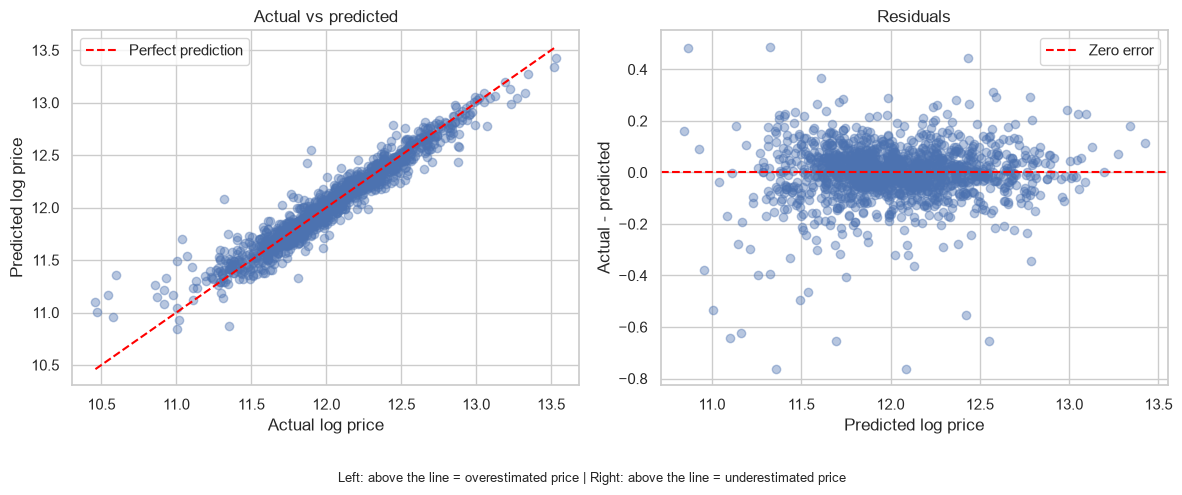

In [65]:
oof_predictions = cross_val_predict(selected_model, X, y, cv=cv, n_jobs=1)
residuals = y.to_numpy() - oof_predictions

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(y, oof_predictions, alpha=0.4)

price_limits = [min(y.min(), oof_predictions.min()), max(y.max(), oof_predictions.max())]

axes[0].plot(price_limits, price_limits, color="red", linestyle="--", label="Perfect prediction")

axes[0].set_xlabel("Actual log price")
axes[0].set_ylabel("Predicted log price")
axes[0].set_title("Actual vs predicted")
axes[0].legend()

axes[1].scatter(oof_predictions, residuals, alpha=0.4)
axes[1].axhline(0, color="red", linestyle="--", label="Zero error")

axes[1].set_xlabel("Predicted log price")
axes[1].set_ylabel("Actual - predicted")
axes[1].set_title("Residuals")
axes[1].legend()

fig.text(0.5, 0.02, "Left: above the line = overestimated price | Right: above the line = underestimated price", ha="center", fontsize=9)

plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

Most predictions follow the diagonal, and residuals are concentrated around zero

Several houses have large errors, especially overestimated prices

## Kaggle submissions

The model selected by cross-validation is fitted on the retained training houses and exported as the main submission

Public scores are used as an external check

In [66]:
final_model = clone(selected_model)
final_model.fit(X, y)

test_log_predictions = final_model.predict(test_X)
test_predictions = np.maximum(np.expm1(test_log_predictions), 0)

submission = pd.DataFrame({"Id": test_ids,
                           "SalePrice": test_predictions})

assert len(submission) == len(test_df)
assert np.isfinite(test_predictions).all()

submission_directory = Path("submissions")
submission_directory.mkdir(exist_ok=True)

selected_model_slug = (selected_model_name.lower().replace(" ", "_").replace("-", "_"))
submission_path = (submission_directory / f"house_prices_{selected_model_slug}.csv")
submission.to_csv(submission_path, index=False)

print("Selected model:", selected_model_name)
print("Submission saved to:", submission_path)

submission.head()

Selected model: Equal Voting
Submission saved to: submissions\house_prices_equal_voting.csv


,Id,SalePrice
0,1461,122261.472669
1,1462,158993.355627
2,1463,182681.264328
3,1464,201782.085470
4,1465,186866.321716


## Five-fold submission

Predictions from five models trained on different training folds are averaged in log-price space

This submission is compared with the model fitted on all retained training houses

In [67]:
fold_log_predictions = []

for train_index, _ in cv.split(X):
    fold_model = clone(selected_model)
    fold_model.fit(X.iloc[train_index], y.iloc[train_index])
    fold_log_predictions.append(fold_model.predict(test_X))

mean_log_predictions = np.mean(fold_log_predictions, axis=0)
fold_prices = np.maximum(np.expm1(mean_log_predictions), 0)

five_fold_submission = pd.DataFrame({"Id": test_ids, "SalePrice": fold_prices})

assert len(five_fold_submission) == len(test_df)
assert np.isfinite(fold_prices).all()

five_fold_slug = (selected_model_name.lower().replace(" ", "_").replace("-", "_"))
five_fold_path = (submission_directory / f"house_prices_{five_fold_slug}_5fold.csv")
five_fold_submission.to_csv(five_fold_path, index=False)

print("Model:", selected_model_name)
print("Submission saved to:", five_fold_path)

five_fold_submission.head()

Model: Equal Voting
Submission saved to: submissions\house_prices_equal_voting_5fold.csv


,Id,SalePrice
0,1461,121121.490989
1,1462,157382.692637
2,1463,185248.102049
3,1464,200485.743848
4,1465,188556.887595


## Export all candidate models

Each candidate is trained on all retained training houses and exported for Kaggle comparison

In [68]:
exported_submissions = []

for name, model in candidate_models.items():
    candidate_slug = name.lower().replace(" ", "_").replace("-", "_")

    candidate_path = (submission_directory / f"house_prices_{candidate_slug}.csv")

    if name == selected_model_name:
        model_submission = submission.copy()
    else:
        fitted_model = clone(model)
        fitted_model.fit(X, y)

        log_predictions = fitted_model.predict(test_X)
        price_predictions = np.maximum(np.expm1(log_predictions), 0)

        model_submission = pd.DataFrame({"Id": test_ids,
                                         "SalePrice": price_predictions})

    assert len(model_submission) == len(test_df)
    assert np.isfinite(model_submission["SalePrice"]).all()

    model_submission.to_csv(candidate_path, index=False)

    exported_submissions.append({"Model": name,
                                 "File": candidate_path.name})

    print("Exported:", name)

pd.DataFrame(exported_submissions)

Exported: CatBoost One-Hot
Exported: CatBoost Native
Exported: RBF SVR
Exported: ElasticNet
Exported: Lasso
Exported: Ridge
Exported: Gradient Boosting
Exported: XGBoost
Exported: LightGBM
Exported: Random Forest
Exported: KNN
Exported: Decision Tree
Exported: Bagging Decision Tree
Exported: PyTorch DNN
Exported: PyTorch DNN Embeddings
Exported: Equal Voting
Exported: Stacking Ridge
Exported: Equal Voting with DNN


,Model,File
0,CatBoost One-Hot,house_prices_catboost_one_hot.csv
1,CatBoost Native,house_prices_catboost_native.csv
2,RBF SVR,house_prices_rbf_svr.csv
3,ElasticNet,house_prices_elasticnet.csv
4,Lasso,house_prices_lasso.csv
5,Ridge,house_prices_ridge.csv
6,Gradient Boosting,house_prices_gradient_boosting.csv
7,XGBoost,house_prices_xgboost.csv
8,LightGBM,house_prices_lightgbm.csv
9,Random Forest,house_prices_random_forest.csv


## Conclusions

- Equal Voting achieved the lowest mean CV RMSE, with only small differences between the ensembles
- Engineered features and outlier removal slightly reduced mean RMSE on the evaluated split
- Categorical embeddings did not improve CV RMSE with the parameters transferred from the one-hot DNN

## Limitations

- The same folds were used for tuning and model selection, so CV results may be optimistic
- Main CV results and OOF plots exclude the two flagged houses
- Small score differences do not establish a reliable ranking
- GPU training results may vary between runs
- The benefit of outlier removal may depend on whether similar unusual houses appear in training and validation